In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt
import cmocean

In [2]:
# import region bounds
from regions import ROSS_ISLAND_BOUNDS

# assign region bounds
x_min = ROSS_ISLAND_BOUNDS["x_min"]
x_max = ROSS_ISLAND_BOUNDS["x_max"]
y_min = ROSS_ISLAND_BOUNDS["y_min"]
y_max = ROSS_ISLAND_BOUNDS["y_max"]

# Load all thickness data

In [3]:
bedmap123_ross_onshelf_rm4 = pd.read_csv("data/bedmap123_ross_onshelf_3M.csv")
bedmap123_ross_onshelf_rm4.shape

(3239963, 12)

# Subset region around Ross Island

In [4]:
bedmap123_ross_island = bedmap123_ross_onshelf_rm4[
    (bedmap123_ross_onshelf_rm4["x"] >= x_min) & (bedmap123_ross_onshelf_rm4["x"] <= x_max) & (bedmap123_ross_onshelf_rm4["y"] >= y_min) & (bedmap123_ross_onshelf_rm4["y"] <= y_max)]

# Look at data
bedmap123_ross_island

,lon,lat,x,y,s,t,b,b_inferred,source,t_fa,x_norm,y_norm
41,170.133300,-78.411670,216463.844340,-1.244552e+06,54.00,320.00,-815.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,310.00,0.816464,0.155448
42,169.183300,-78.133330,242801.567307,-1.270798e+06,35.00,218.00,-920.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,208.00,0.842802,0.129202
43,168.950000,-78.075000,249201.416991,-1.276084e+06,31.00,156.00,-902.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,146.00,0.849201,0.123916
44,168.666700,-78.010000,256910.452033,-1.281834e+06,23.00,123.00,-887.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,113.00,0.856910,0.118166
45,168.366700,-77.966670,264577.987681,-1.285131e+06,26.00,111.00,-836.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,101.00,0.864578,0.114869
...,...,...,...,...,...,...,...,...,...,...,...,...
3239958,171.568072,-77.409951,201365.222703,-1.358404e+06,-14.30,213.01,-227.31,False,UTIG_2010_ICECAP_AIR_BM3.csv,203.01,0.801365,0.041596
3239959,171.568076,-77.409746,201368.432114,-1.358427e+06,-13.86,212.07,-225.93,False,UTIG_2010_ICECAP_AIR_BM3.csv,202.07,0.801368,0.041573
3239960,171.568079,-77.409540,201371.681352,-1.358449e+06,-14.60,210.89,-225.50,False,UTIG_2010_ICECAP_AIR_BM3.csv,200.89,0.801372,0.041551
3239961,171.568083,-77.409331,201374.955233,-1.358472e+06,-15.03,213.22,-228.25,False,UTIG_2010_ICECAP_AIR_BM3.csv,203.22,0.801375,0.041528


In [5]:
bedmap123_ross_island["t_fa"].describe()

count    242225.000000
mean        202.271343
std          96.502858
min         -10.000000
25%         144.550000
50%         201.566519
75%         280.450000
max        2154.640000
Name: t_fa, dtype: float64

# Load Modis data for background

In [6]:
# tensor format so leave as is
modis_ross = torch.load("data/modis/moa125_2014_hp1_v01_ross_with_grid_no_ocean.pt", weights_only = False)

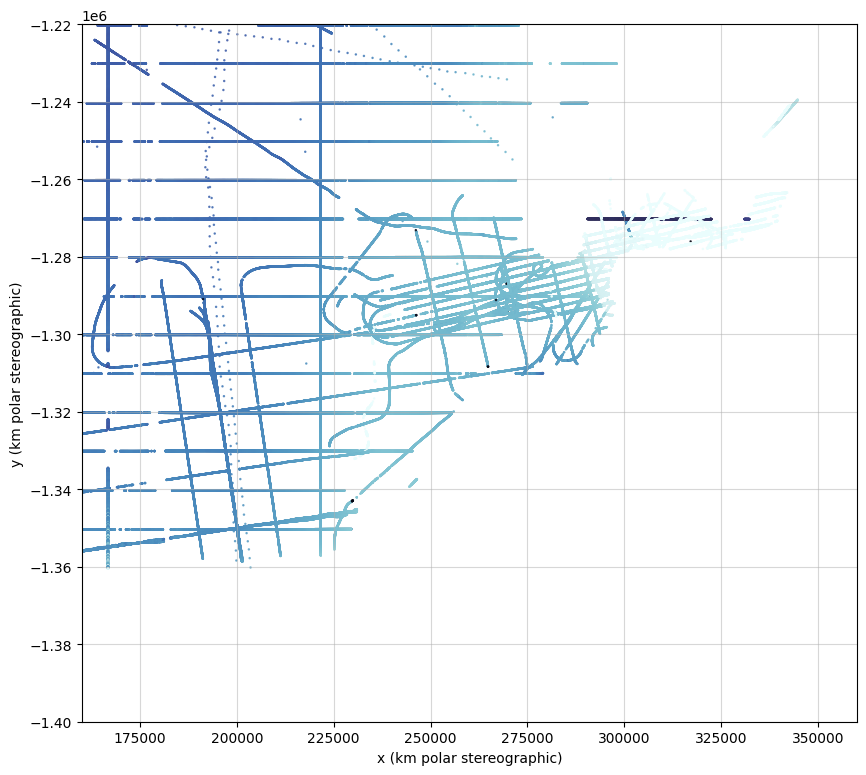

In [7]:
MODIS_background = False

fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
ax.scatter(
    bedmap123_ross_island['x'], 
    bedmap123_ross_island['y'], 
    c = bedmap123_ross_island['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

# Removal step 1: threshold clean

In [8]:
# Inspect outliers
rm1_removal_candidates = bedmap123_ross_island[bedmap123_ross_island["t_fa"] > 500]

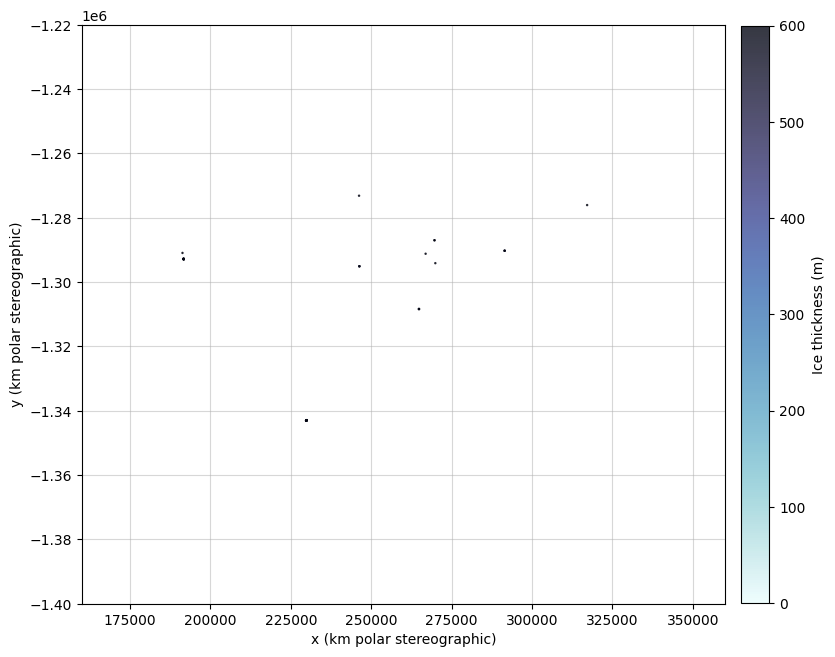

In [12]:
MODIS_background = False

fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    rm1_removal_candidates['x'], 
    rm1_removal_candidates['y'], 
    c = rm1_removal_candidates['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [13]:
bedmap123_ross_island_rm1 = bedmap123_ross_island[bedmap123_ross_island["t_fa"] < 500]

# Inspect sources

In [14]:
bedmap123_ross_island_rm1["source"].value_counts()

source
UTIG_2010_ICECAP_AIR_BM3.csv       134195
LDEO_2015_ROSETTA_AIR_BM3.csv      103383
NASA_2011_ICEBRIDGE_AIR_BM2.csv      4415
BEDMAP1_1966-2000_AIR_BM1.csv         192
Name: count, dtype: int64

In [15]:
# Generate subsets for visualisation
bedmap123_ross_island_rm1_bm1 = bedmap123_ross_island_rm1[bedmap123_ross_island_rm1["source"] == "BEDMAP1_1966-2000_AIR_BM1.csv"]
bedmap123_ross_island_rm1_utig = bedmap123_ross_island_rm1[bedmap123_ross_island_rm1["source"] == "UTIG_2010_ICECAP_AIR_BM3.csv"]
bedmap123_ross_island_rm1_nasa = bedmap123_ross_island_rm1[bedmap123_ross_island_rm1["source"] == "NASA_2011_ICEBRIDGE_AIR_BM2.csv"]
bedmap123_ross_island_rm1_ldeo = bedmap123_ross_island_rm1[bedmap123_ross_island_rm1["source"] == "LDEO_2015_ROSETTA_AIR_BM3.csv"]

## Visualise Bedmap1 only

Does not conflict much but overlaps with other surveys so we may remove due to age.

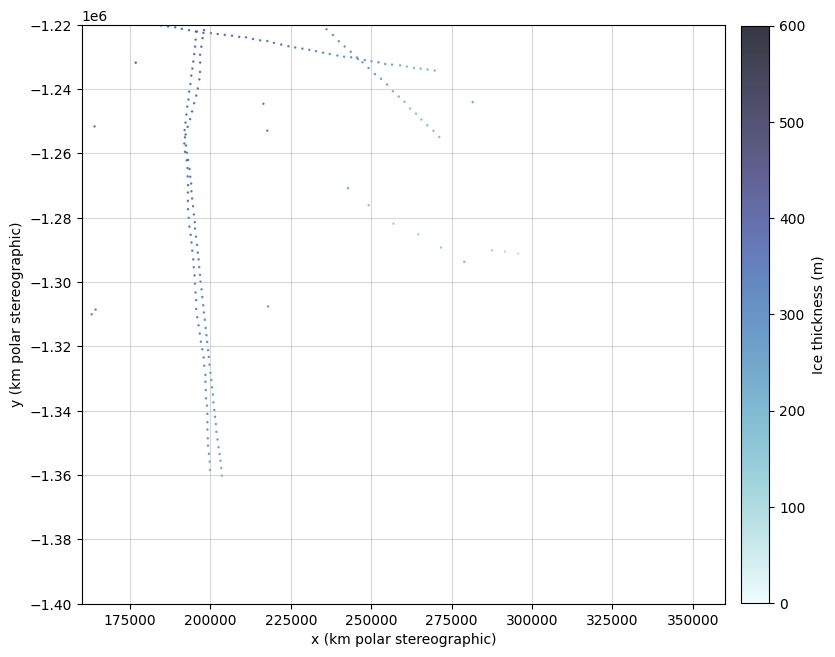

In [16]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    bedmap123_ross_island_rm1_bm1['x'], 
    bedmap123_ross_island_rm1_bm1['y'], 
    c = bedmap123_ross_island_rm1_bm1['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

# NASA

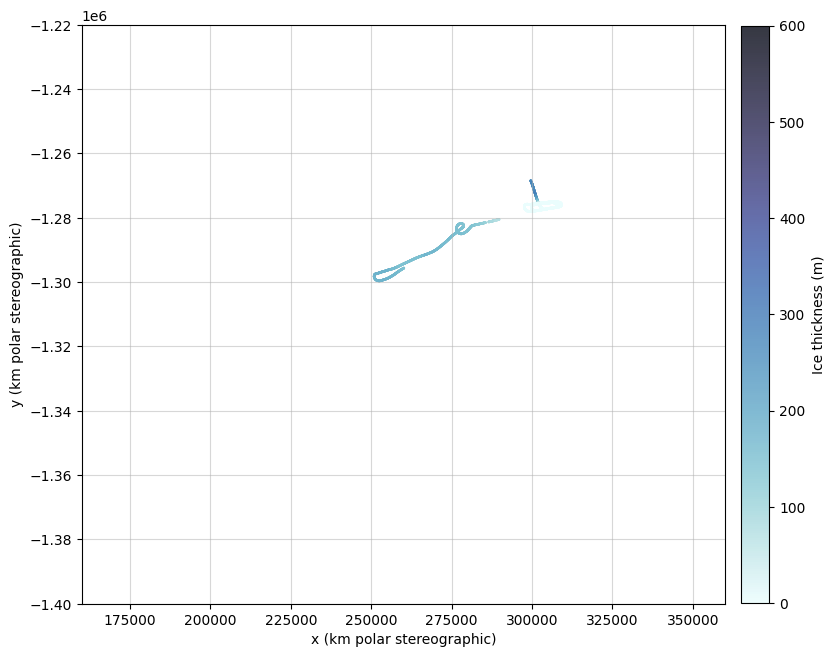

In [17]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    bedmap123_ross_island_rm1_nasa['x'], 
    bedmap123_ross_island_rm1_nasa['y'], 
    c = bedmap123_ross_island_rm1_nasa['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [18]:
rm2_removal_candidates = bedmap123_ross_island_rm1[
    (bedmap123_ross_island_rm1["source"] == "NASA_2011_ICEBRIDGE_AIR_BM2.csv") &
    (bedmap123_ross_island_rm1["t_fa"] > 200) & 
    (bedmap123_ross_island_rm1["x"] > 290_000)]

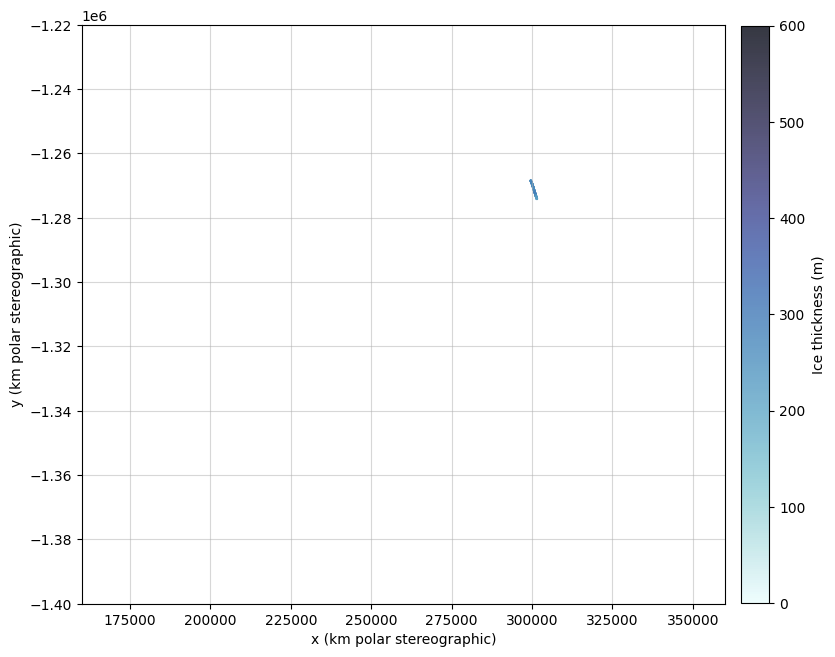

In [19]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    rm2_removal_candidates['x'], 
    rm2_removal_candidates['y'], 
    c = rm2_removal_candidates['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [20]:
bedmap123_ross_island_rm2 = bedmap123_ross_island_rm1[
    ~(
    (bedmap123_ross_island_rm1["source"] == "NASA_2011_ICEBRIDGE_AIR_BM2.csv") &
    (bedmap123_ross_island_rm1["t_fa"] > 200) & 
    (bedmap123_ross_island_rm1["x"] > 290_000)
    )]

# UTIG

Step RM1 removed some of the oddly placed starting points

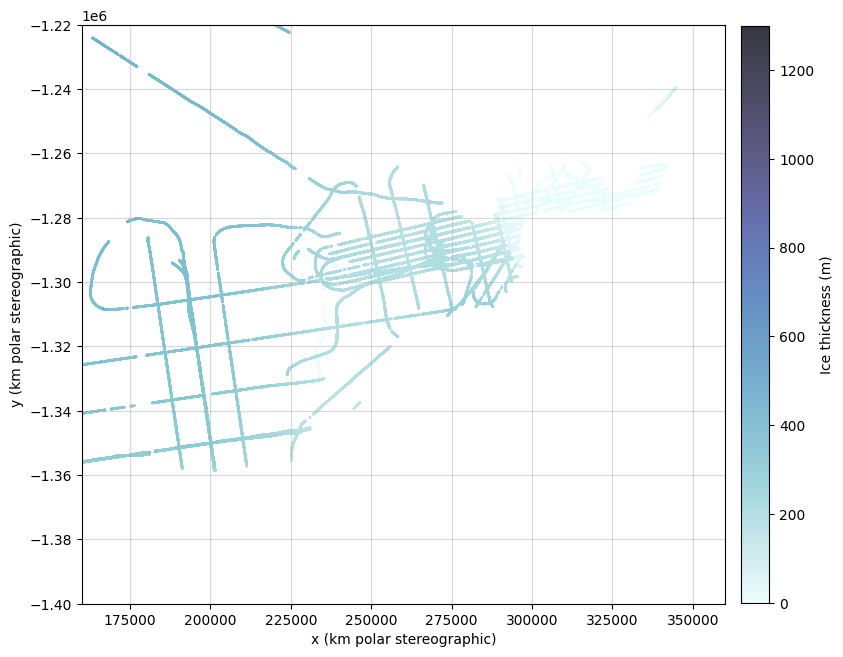

In [21]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) SMB on top (draw second)
sc = ax.scatter(
    bedmap123_ross_island_rm1_utig['x'], 
    bedmap123_ross_island_rm1_utig['y'], 
    c = bedmap123_ross_island_rm1_utig['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 1300 # saturate at 1200
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [22]:
rm3_removal_candidates = bedmap123_ross_island_rm2[
    (bedmap123_ross_island_rm2["source"] == "UTIG_2010_ICECAP_AIR_BM3.csv") & 
    (bedmap123_ross_island_rm2["t_fa"] < 10) &
    (bedmap123_ross_island_rm2["x"] < 285_000)]

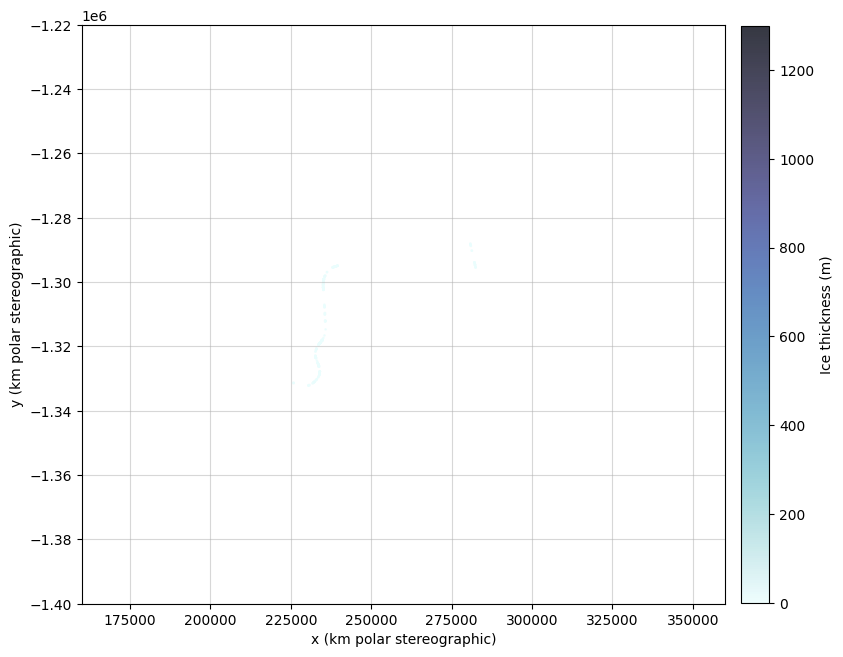

In [23]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) SMB on top (draw second)
sc =ax.scatter(
    rm3_removal_candidates['x'], 
    rm3_removal_candidates['y'], 
    c = rm3_removal_candidates['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 1300 # saturate at 1200
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [24]:
# Remove
bedmap123_ross_island_rm3 = bedmap123_ross_island_rm2[
    ~(
    (bedmap123_ross_island_rm2["source"] == "UTIG_2010_ICECAP_AIR_BM3.csv") & 
    (bedmap123_ross_island_rm2["t_fa"] < 10) &
    (bedmap123_ross_island_rm2["x"] < 285_000)
    )]

# LDEO

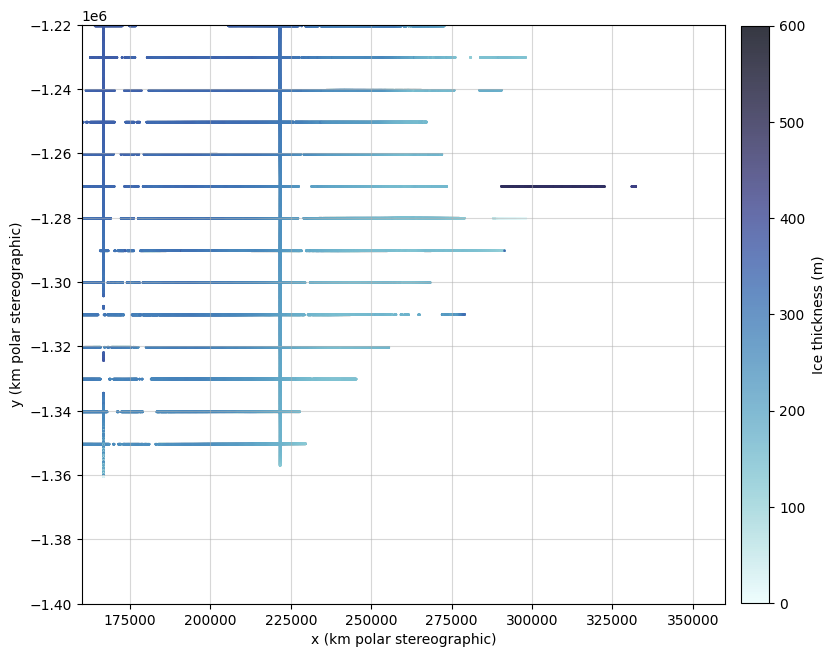

In [25]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    bedmap123_ross_island_rm1_ldeo['x'], 
    bedmap123_ross_island_rm1_ldeo['y'], 
    c = bedmap123_ross_island_rm1_ldeo['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [26]:
rm4_removal_candidates = bedmap123_ross_island_rm3[
    (bedmap123_ross_island_rm3["source"] == "LDEO_2015_ROSETTA_AIR_BM3.csv") & 
    (bedmap123_ross_island_rm3["x"] > 275_000) &
    (bedmap123_ross_island_rm3["y"] < -1_260_000) &
    (bedmap123_ross_island_rm3["y"] > -1_280_000)]

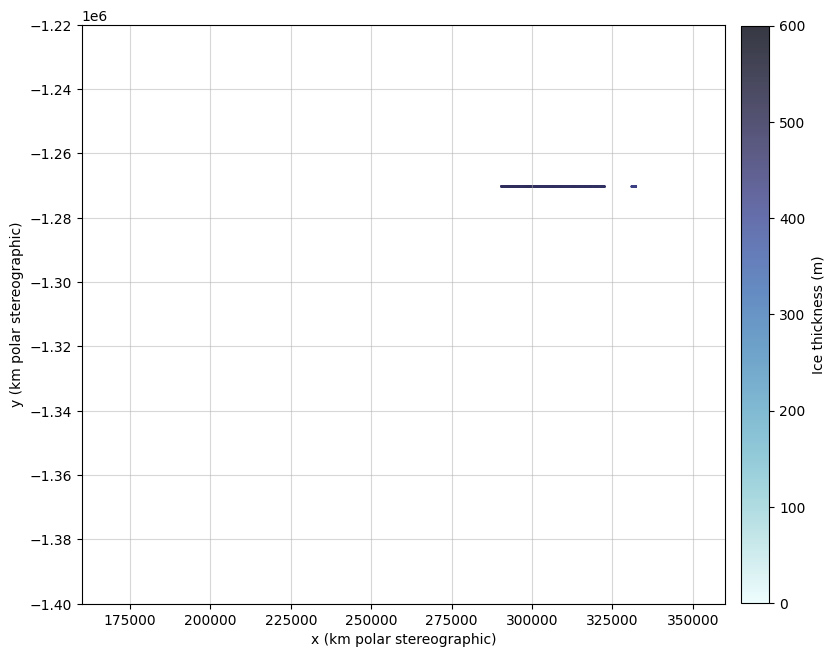

In [27]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    rm4_removal_candidates['x'], 
    rm4_removal_candidates['y'], 
    c = rm4_removal_candidates['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [28]:
bedmap123_ross_island_rm4 = bedmap123_ross_island_rm3[
    ~(
    (bedmap123_ross_island_rm3["source"] == "LDEO_2015_ROSETTA_AIR_BM3.csv") & 
    (bedmap123_ross_island_rm3["x"] > 275_000) &
    (bedmap123_ross_island_rm3["y"] < -1_260_000) &
    (bedmap123_ross_island_rm3["y"] > -1_280_000)
    )]

# Final version

In [29]:
MODIS_background = True

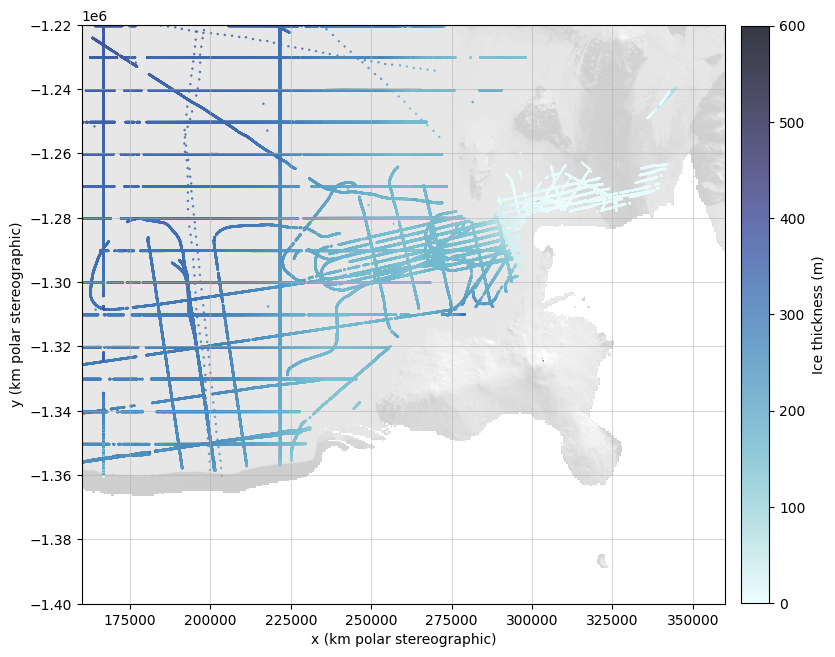

In [30]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    bedmap123_ross_island_rm4['x'], 
    bedmap123_ross_island_rm4['y'], 
    c = bedmap123_ross_island_rm4['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [31]:
bedmap123_ross_island_rm4

,lon,lat,x,y,s,t,b,b_inferred,source,t_fa,x_norm,y_norm
41,170.133300,-78.411670,216463.844340,-1.244552e+06,54.00,320.00,-815.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,310.00,0.816464,0.155448
42,169.183300,-78.133330,242801.567307,-1.270798e+06,35.00,218.00,-920.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,208.00,0.842802,0.129202
43,168.950000,-78.075000,249201.416991,-1.276084e+06,31.00,156.00,-902.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,146.00,0.849201,0.123916
44,168.666700,-78.010000,256910.452033,-1.281834e+06,23.00,123.00,-887.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,113.00,0.856910,0.118166
45,168.366700,-77.966670,264577.987681,-1.285131e+06,26.00,111.00,-836.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,101.00,0.864578,0.114869
...,...,...,...,...,...,...,...,...,...,...,...,...
3239958,171.568072,-77.409951,201365.222703,-1.358404e+06,-14.30,213.01,-227.31,False,UTIG_2010_ICECAP_AIR_BM3.csv,203.01,0.801365,0.041596
3239959,171.568076,-77.409746,201368.432114,-1.358427e+06,-13.86,212.07,-225.93,False,UTIG_2010_ICECAP_AIR_BM3.csv,202.07,0.801368,0.041573
3239960,171.568079,-77.409540,201371.681352,-1.358449e+06,-14.60,210.89,-225.50,False,UTIG_2010_ICECAP_AIR_BM3.csv,200.89,0.801372,0.041551
3239961,171.568083,-77.409331,201374.955233,-1.358472e+06,-15.03,213.22,-228.25,False,UTIG_2010_ICECAP_AIR_BM3.csv,203.22,0.801375,0.041528


# Export

In [32]:
bedmap123_ross_island_rm4.to_csv("data/bedmap123_ross_island_cleaned_240k.csv", index = False)